In [1]:
# numpy helps us work with numbers and arrays
import numpy as np

# pandas lets us store data in a neat table, like a spreadsheet
import pandas as pd

# matplotlib is what we use to draw charts and pictures
import matplotlib.pyplot as plt

# make_blobs generates a simple practice dataset made of natural groups
from sklearn.datasets import make_blobs

# KMeans is the first clustering algorithm we're covering
from sklearn.cluster import KMeans

# AgglomerativeClustering is how scikit-learn runs Hierarchical Clustering
from sklearn.cluster import AgglomerativeClustering

# these two let us build and draw a dendrogram (the merge tree picture)
from scipy.cluster.hierarchy import linkage, dendrogram

# lock in the "randomness" so everyone gets the exact same numbers every time
np.random.seed(42)

# a simple message to confirm everything loaded properly
print("Ready to go!")

Ready to go!


In [2]:
# the 3 rough "centers" our fake customer groups will be built around
group_centers = [[-4, -2], [0, 3], [4, -3]]

# make_blobs generates points scattered around each center, like real customers
# would naturally cluster around a few typical spending habits
raw_points, _ = make_blobs(n_samples=180, centers=group_centers, cluster_std=0.8, random_state=42)

# turn the first raw column into a realistic-looking dollar amount
# np.clip stops any value from going below $50 (nobody spends negative money)
annual_spend = np.clip(raw_points[:, 0] * 150 + 950, 50, None).round(0)

# turn the second raw column into a realistic-looking visit count
# np.clip stops any value from going below 1 visit per month
visits_per_month = np.clip(raw_points[:, 1] * 1.3 + 12, 1, None).round(1)

# put both features into one table
customers = pd.DataFrame({
    "annual_spend": annual_spend,
    "visits_per_month": visits_per_month
})

# show the first 10 rows so we can see what it looks like
customers.head(10)

,annual_spend,visits_per_month
0,1432.0,8.6
1,977.0,17.3
2,831.0,15.3
3,1451.0,8.4
4,823.0,16.4
5,1520.0,6.8
6,375.0,7.4
7,862.0,16.1
8,1648.0,8.8
9,1584.0,7.5


In [10]:
X = customers[["annual_spend", "visits_per_month"]]
kmeans = KMeans(n_clusters = 3 , random_state = 42 , n_init = 10)
kmeans.fit(X)
cluster_label = kmeans.labels_
centroids_labels = kmeans.cluster_centers_
customers["cluster"] = cluster_label
customers.head(10)

,annual_spend,visits_per_month,cluster
0,1432.0,8.6,1
1,977.0,17.3,0
2,831.0,15.3,0
3,1451.0,8.4,1
4,823.0,16.4,0
5,1520.0,6.8,1
6,375.0,7.4,2
7,862.0,16.1,0
8,1648.0,8.8,1
9,1584.0,7.5,1


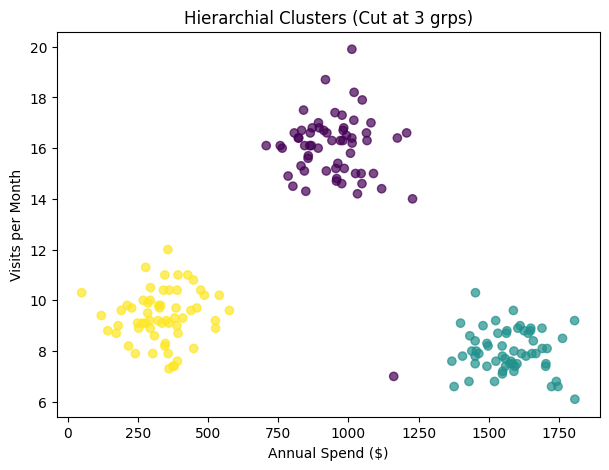

In [13]:
hierarchial = AgglomerativeClustering(n_clusters=3)
hierarchial_labels = hierarchial.fit_predict(X)
plt.figure(figsize=(7,5))
plt.scatter(X.iloc[:,0],X.iloc[:,1], c=hierarchial_labels, cmap="viridis" ,alpha=0.7)
plt.xlabel("Annual Spend ($)")
plt.ylabel("Visits per Month")
plt.title("Hierarchial Clusters (Cut at 3 grps)")
plt.show()